# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?
- ¿Qué representa en el caso del filtro de promedio móvil?

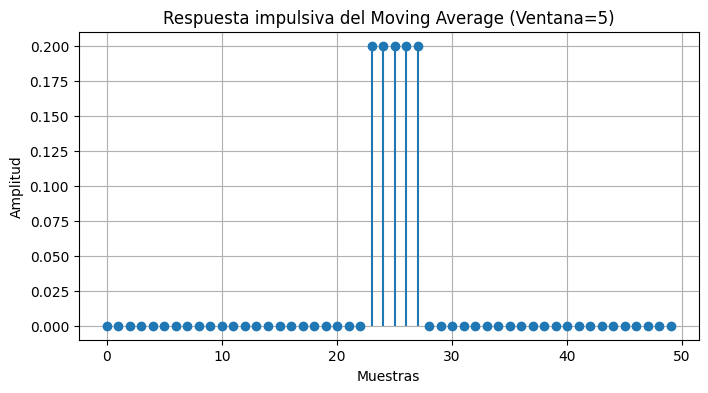

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(x, window_size):
    # kernel de unos dividido por la ventana
    kernel = np.ones(window_size) / window_size
    # convolucion
    return np.convolve(x, kernel, mode='same')

# impulso unitario en la mitad
impulso = np.zeros(50)
impulso[25] = 1

# respuesta
window_size = 5
respuesta_impulsiva = moving_average(impulso, window_size)

# gráfico
plt.figure(figsize=(8, 4))
plt.stem(respuesta_impulsiva, basefmt=" ")
plt.title(f"Respuesta impulsiva del Moving Average (Ventana={window_size})")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()

La rta impulsiva la obtengo inyectando a la entrada un impulso unitario y midiendo la salida, así genero la firma de mi sistema.
La rta de la media movil representa el kernel, osea, un arreglo de N valores de 1/N amplitud, siendo N el tamaño de la ventana seteada.

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?


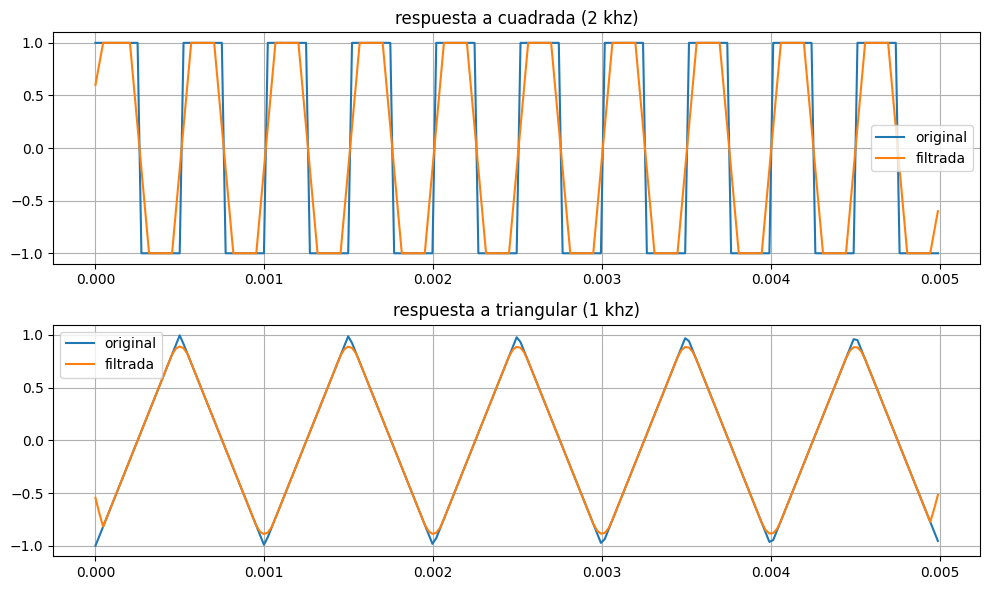

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def moving_average(x, window_size):
    # kernel de unos dividido por la ventana
    kernel = np.ones(window_size) / window_size
    # convolucion
    return np.convolve(x, kernel, mode='same')

# vector de tiempo (5 milisegundos a 44.1 khz)
fs = 44100
t = np.arange(0, 0.005, 1/fs)

# cuadrada de 2 khz (amplitud 1)
cuadrada = signal.square(2 * np.pi * 2000 * t)

# triangular de 1 khz (amplitud 1, simetria 0.5)
triangular = signal.sawtooth(2 * np.pi * 1000 * t, 0.5)

# filtros
ventana = 5
cuad_filtrada = moving_average(cuadrada, ventana)
trian_filtrada = moving_average(triangular, ventana)

# figura
plt.figure(figsize=(10, 6))

# grafico cuadrada
plt.subplot(2, 1, 1)
plt.plot(t, cuadrada, label="original")
plt.plot(t, cuad_filtrada, label="filtrada")
plt.title("respuesta a cuadrada (2 khz)")
plt.legend()
plt.grid(True)

# grafico triangular
plt.subplot(2, 1, 2)
plt.plot(t, triangular, label="original")
plt.plot(t, trian_filtrada, label="filtrada")
plt.title("respuesta a triangular (1 khz)")
plt.legend()
plt.grid(True)

# muestra
plt.tight_layout()
plt.show()

Se ve claramente como el filtro suaviza la respuesta tanto de la onda cuadrada como la triangular, actuando como filtro pasabajos. Atenúa los cambios bruscos, en la cuadrada generando rampas de subida diagonales, y en la triangular evitando las transiciones rápidas en los vértices. A mayor ventana, mayor recorte.

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando la funcion fijo() de ejemplo.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficar todas las señales calculadas

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?
    - ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

error de conv manual float: 0.0
error de conv manual fijo: 7.088831238177828e-05

tiempo numpy: 0.0049 s
tiempo float: 0.5846 s
tiempo fijo: 5.2992 s


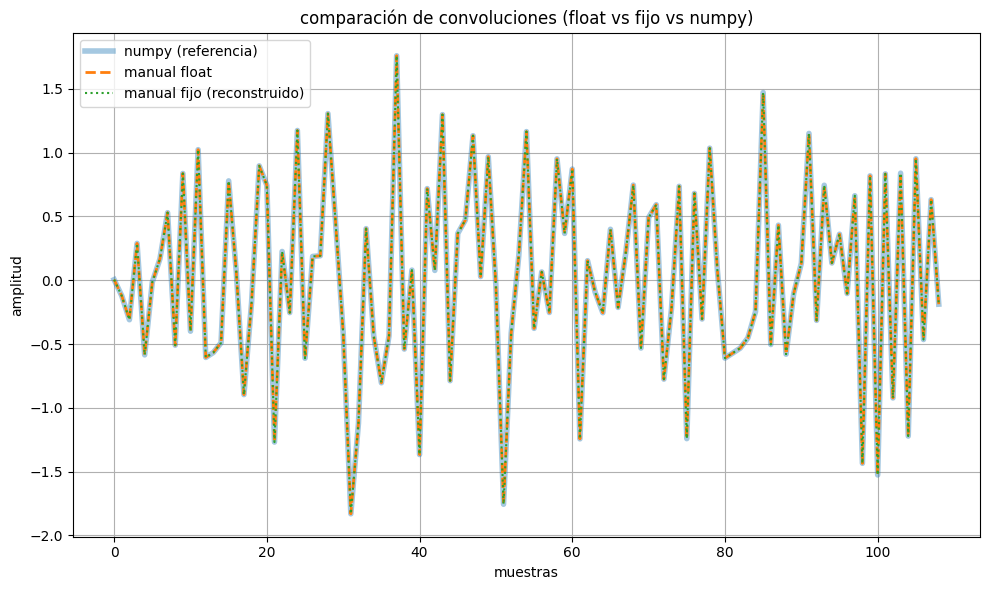

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

def convolucion_float(x, h):
    # salida flotante
    y = np.zeros(len(x) + len(h) - 1)

    # bucle manual
    for i in range(len(x)):
        for j in range(len(h)):
            y[i+j] += x[i] * h[j]
    return y

def convolucion_fijo(x, h):
    # acumulador de 64 bits para evitar overflow en las sumas
    y = np.zeros(len(x) + len(h) - 1, dtype=np.int64)

    # convierte a enteros q1.15
    x_fijo = np.array([fijo(v) for v in x], dtype=np.int32)
    h_fijo = np.array([fijo(v) for v in h], dtype=np.int32)

    # bucle manual entero
    for i in range(len(x)):
        for j in range(len(h)):
            # cast a 64 bits (registro MAC?)
            y[i+j] += np.int64(x_fijo[i]) * np.int64(h_fijo[j])

    # devuelve a formato q1.15 descartando la parte baja
    return y >> 15

# señales de prueba randoms entre -1 y 1
señal = np.random.uniform(-1, 1, 100)
kernel = np.random.uniform(-1, 1, 10)

# calculos
y_numpy = np.convolve(señal, kernel)
y_float = convolucion_float(señal, kernel)
y_fijo = convolucion_fijo(señal, kernel)

# salida fija a float para calcular  error
y_fijo_float = y_fijo / 32768.0

# error absoluto maximo (respecto a numpy como valor verdadero)
error_float = np.max(np.abs(y_numpy - y_float))
error_fijo = np.max(np.abs(y_numpy - y_fijo_float))

print(f"error de conv manual float: {error_float}")
print(f"error de conv manual fijo: {error_fijo}")

# medicion de tiempos con lambda para no definir wrapper
# "Python lambdas are only a shorthand notation if you’re too lazy to define a function"
t_numpy = timeit.timeit(lambda: np.convolve(señal, kernel), number=1000)
t_float = timeit.timeit(lambda: convolucion_float(señal, kernel), number=1000)
t_fijo = timeit.timeit(lambda: convolucion_fijo(señal, kernel), number=1000)

print(f"\ntiempo numpy: {t_numpy:.4f} s")
print(f"tiempo float: {t_float:.4f} s")
print(f"tiempo fijo: {t_fijo:.4f} s")

# graficos
plt.figure(figsize=(10, 6))

# dibujo modificando el grosor y el estilo de linea
plt.plot(y_numpy, label='numpy (referencia)', linewidth=4, alpha=0.4)
plt.plot(y_float, label='manual float', linewidth=2, linestyle='--')
plt.plot(y_fijo_float, label='manual fijo (reconstruido)', linestyle=':')

plt.title("comparación de convoluciones (float vs fijo vs numpy)")
plt.xlabel("muestras")
plt.ylabel("amplitud")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

La principal diferencia es el tiempo de ejecución, arrasando totalmente numpy con resopecto a los cálculos "manuales". En cuanto a errores, no considero significativo el error del punto fijo para aplicaciones normales, lo que sí sería clave a considerar es el tiempo de cada operación según la aplicación en la que se encuentre, y si se puede permitir o no realizar los cálculos de esta forma en python o si habría que codear en C simulando la librería numpy si no tengo FPU en el micro.